In [1]:
import pandas as pd  

# Load the dataset  
df = pd.read_csv('./data/mini_project_2_data.csv')

## Preliminary Data Exploration

In [2]:
# Take a random peek at the data
df.sample(5, random_state=42)

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
30946,21554,0.0,Changi,December,August,17.0,August,21.0,Malaysia,Yes,King,USD$ 591.69,Website,2,2.0
40207,103322,0.0,Changi,November,September,29.0,October,2.0,Japan,Yes,Single,NaN,Website,1,1.0
85806,37941,0.0,Orchard,October,November,11.0,November,13.0,Indonesia,Yes,NaN,USD$ 887.22,Agent,1,2.0
100241,22598,0.0,Orchard,December,October,27.0,October,29.0,Indonesia,Yes,King,NaN,Website,2,0.0
109992,44498,0.0,Orchard,March,August,3.0,August,4.0,Indonesia,Yes,President Suite,USD$ 1335.01,Email,1,3.0


In [3]:
# Summarise structure of data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119391 entries, 0 to 119390
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   booking_id      119391 non-null  int64  
 1   no_show         119390 non-null  float64
 2   branch          119390 non-null  object 
 3   booking_month   119390 non-null  object 
 4   arrival_month   119390 non-null  object 
 5   arrival_day     119390 non-null  float64
 6   checkout_month  119390 non-null  object 
 7   checkout_day    119390 non-null  float64
 8   country         119390 non-null  object 
 9   first_time      119390 non-null  object 
 10  room            97778 non-null   object 
 11  price           94509 non-null   object 
 12  platform        119390 non-null  object 
 13  num_adults      119390 non-null  object 
 14  num_children    119390 non-null  float64
dtypes: float64(4), int64(1), object(10)
memory usage: 13.7+ MB


**Observations**

Our dataset contains 119391 rows and 15 columns. Its columns consist of a mix of `object` and numerical (`int64`, `float64`) datatypes. 

On missing values:
- Most columns have null entries, with the exception of `booking_id`.
- I suspect that there may be a null row in the dataset as most columns have at least one null entry.
- `room` and `price` columns have a large portion of missing values at ~18% and ~21% respectively.


In [4]:
# Detect missing values
df.isnull().sum()

booking_id            0
no_show               1
branch                1
booking_month         1
arrival_month         1
arrival_day           1
checkout_month        1
checkout_day          1
country               1
first_time            1
room              21613
price             24882
platform              1
num_adults            1
num_children          1
dtype: int64

In [5]:
# Display summary statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
booking_id,119391.0,59695.000000,34465.357332,0.0,29847.5,59695.0,89542.5,119390.0
no_show,119390.0,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
arrival_day,119390.0,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
checkout_day,119390.0,14.250507,11.063697,-31.0,7.0,15.0,23.0,31.0
num_children,119390.0,0.871229,0.779796,0.0,0.0,1.0,1.0,3.0


**Observations**: 
- `booking_id` is a row identifier with min 0, max 119390 and mean 59695. It is just integers 0,1,...,119390 in shuffled ordered. It is not a predictive feature and should be dropped.
- `no_show` mean = 0.37. The dataset is mildly imbalanced. 
- `checkout_day` min = -31.0. This column has negative value(s) that can be fixed by taking the absolute value(s).
- `price` is absent from summary statistics as it is stored as an `object`. 

In [6]:
# Confirm dataset is mildly imbalanced
df['no_show'].value_counts()

no_show
0.0    75166
1.0    44224
Name: count, dtype: int64

**Observation**: The `no_show` column is binary. The split is 75,166 / 44,224 (~63% / 37%), confirming that dataset is mildly imbalanced. This is well above the ~10–20% minority range where resampling becomes worthwhile, so resampling is not applied.



In [7]:
# Check for duplicate rows (exclude `booking_id` column, otherwise every row is distinct)
features_df = df.drop(columns='booking_id')
features_df.duplicated(keep=False).sum()

np.int64(1514)

In [8]:
# Show all duplicate rows, grouped so matching rows sit together
is_duplicate = features_df.duplicated(keep=False)
features_df[is_duplicate].sort_values(by=list(features_df.columns))

,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
70475,0.0,Changi,April,April,17.0,April,18.0,Indonesia,Yes,King,NaN,Website,2,0.0
114041,0.0,Changi,April,April,17.0,April,18.0,Indonesia,Yes,King,NaN,Website,2,0.0
15693,0.0,Changi,April,April,17.0,April,18.0,Japan,Yes,King,NaN,Agent,1,2.0
98808,0.0,Changi,April,April,17.0,April,18.0,Japan,Yes,King,NaN,Agent,1,2.0
12995,0.0,Changi,April,August,3.0,August,4.0,Indonesia,Yes,King,NaN,Website,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103743,1.0,Orchard,September,May,12.0,May,13.0,China,Yes,King,NaN,Website,1,2.0
44558,1.0,Orchard,September,October,1.0,October,3.0,China,Yes,Single,NaN,Phone,1,0.0
107415,1.0,Orchard,September,October,1.0,October,3.0,China,Yes,Single,NaN,Phone,1,0.0
766,1.0,Orchard,September,October,16.0,October,18.0,China,Yes,King,NaN,Website,2,1.0


In [9]:
# Check if all duplicate rows are missing price data
df.loc[is_duplicate, 'price'].isna().all()

np.True_

**Observations**: 

- There are 1514 rows (~1.27% of data)  that are duplicates of each other. 
- All duplicate rows have missing `price` data. These are most likely genuine, separate bookings whose price were simply not recorded- i.e. not duplicate entries.

**Conclusion**:

- I opt to keep the duplicate rows since they are highly likely to be genuine separate bookings. Also at ~1.27% of the data, the impact of keeping them is negligible.


In [10]:
# Check if null row exists (exlude `booking_id` column)
null_row = df.drop(columns='booking_id').isnull().all(axis=1)
df[null_row]

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
111598,115536,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Delete null row
df = df[~null_row].reset_index(drop=True)   

# Verify deletion
df.drop(columns='booking_id').isnull().all(axis=1).sum()   #  is 0 if deleted

np.int64(0)

**Observation**: There exist a single null row where every column is missing a value except for `booking_id`. The row contains no meaningful data and is removed.

## Univariate Analysis

### `branch`, `country`, `first_time`, `platform` and `num_children`

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

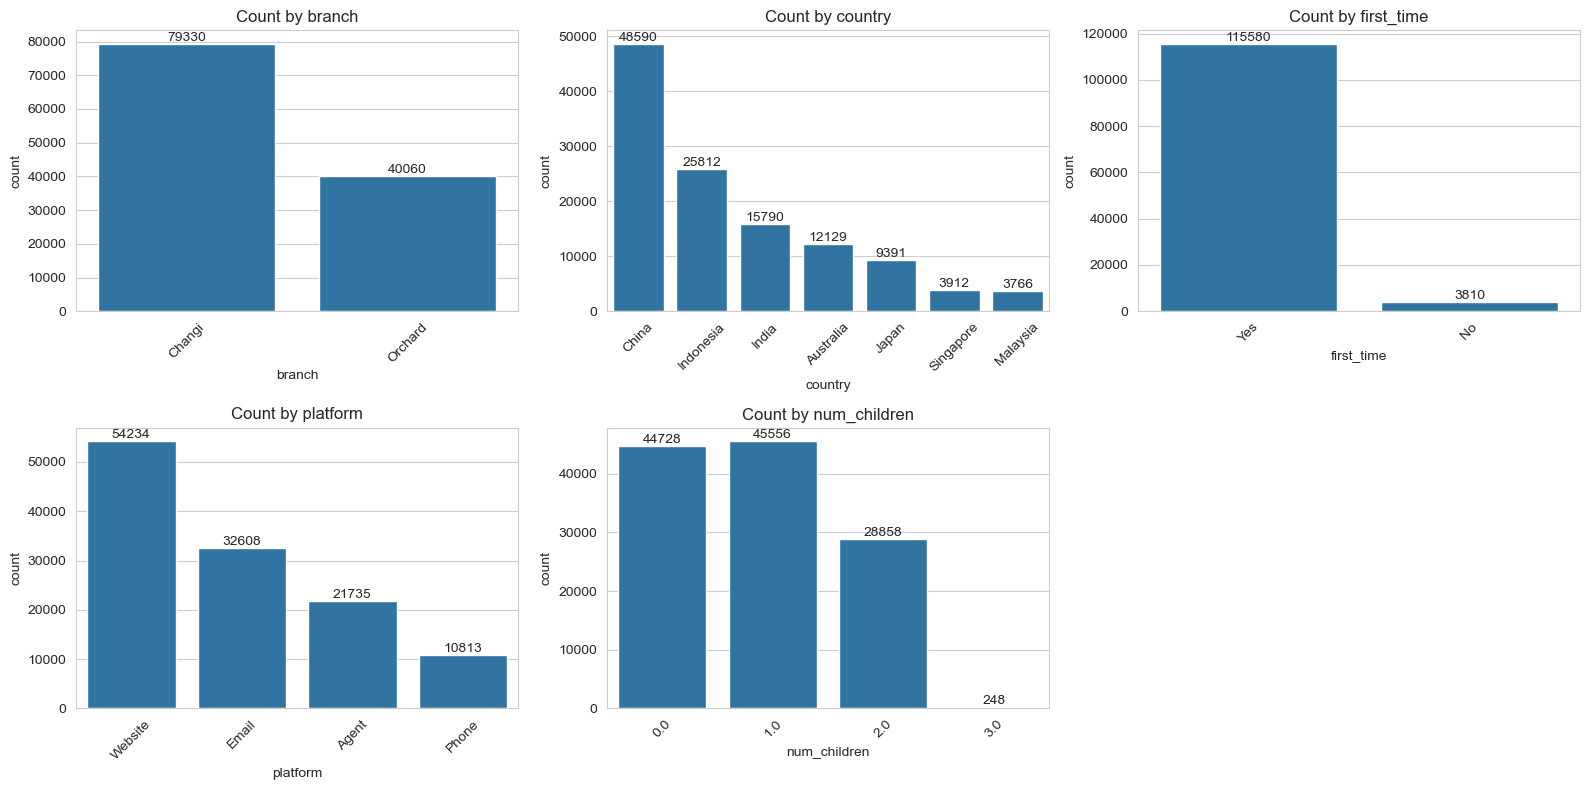

In [13]:
# Create bar charts for clean columns (no missing values, negative values etc)

# Identify the clean columns
clean_cols = ['branch', 'country', 'first_time', 'platform', 'num_children']

# Identify columns where I sort their bars by descending order (exclude num_children)
nominal = {'branch', 'country', 'first_time', 'platform'}   

# Set the aesthetic style of the plots
sns.set_style("whitegrid")

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(clean_cols):
    s = df[col].fillna('Missing') # also plot missing values (if any)
    order = s.value_counts().index if col in nominal else sorted(s.unique())
    sns.countplot(x=s, order=order, ax=axes[i])
    axes[i].bar_label(axes[i].containers[0])
    axes[i].set_title(f'Count by {col}'); axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(clean_cols), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout(); plt.show()

**Observation**: 

`branch`, `country`, `first_time`, `platform` and `num_children` are columns with clean data (no missing values, negative values & outliers etc).

For each of the columns:

- `branch` has only two values, Changi and Orchard. ~66% of hotel bookings are for Changi and ~34% are for Orchard. No missing values.
- `country`: China contributes the largest portion bookings at ~41%. Singapore and Malaysia are smallest at ~3% each.
- `first_time`: Overwhelming majority of bookings are from first timers at ~97%.
- `platform`: Website (~45%) is the most popular platform for booking, followed by email (~27%), agent (~18%) and phone (~9%).
- `num_children`: There are very few bookings (~0.2%) from families with `num_children`= 3.

### `booking_month`, `arrival_month`, `arrival_day`, `checkout_month` and `checkout_day`

In [14]:
# Inspect unique entries in `arrival_month`
df['arrival_month'].value_counts()

arrival_month
August       13695
July         12515
May          11684
October      11009
April        10966
             ...  
MAY              1
SeptEMber        1
ApRiL            1
OcTobeR          1
FeBruaRy         1
Name: count, Length: 88, dtype: int64

In [15]:
# Fix and standardize the uppercasing and lowercasing problem
df['arrival_month'] = df['arrival_month'].str.title()

# Verify 'arrival_month` is cleaned
df['arrival_month'].value_counts()

arrival_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929
Name: count, dtype: int64

**Observation**: `arrival_month` had 88 unique entries due to inconsistent casing (e.g. `MaY`, `JunE`). I standardized the casing with `.str.title()`, collapsing it back to the 12 correct months.


In [16]:
# Inspect unique entries in `checkout_day`
df['checkout_day'].value_counts()

checkout_day
 11.0    4458
 18.0    4248
 20.0    4207
 27.0    4006
 4.0     3972
         ... 
-12.0     157
-13.0     154
-30.0     151
-5.0      145
-31.0      87
Name: count, Length: 62, dtype: int64

In [17]:
# Convert all negative checkout days to positive days by taking abs
df['checkout_day'] = df['checkout_day'].abs()

# Verify changes
df['checkout_day'].nunique() 

31

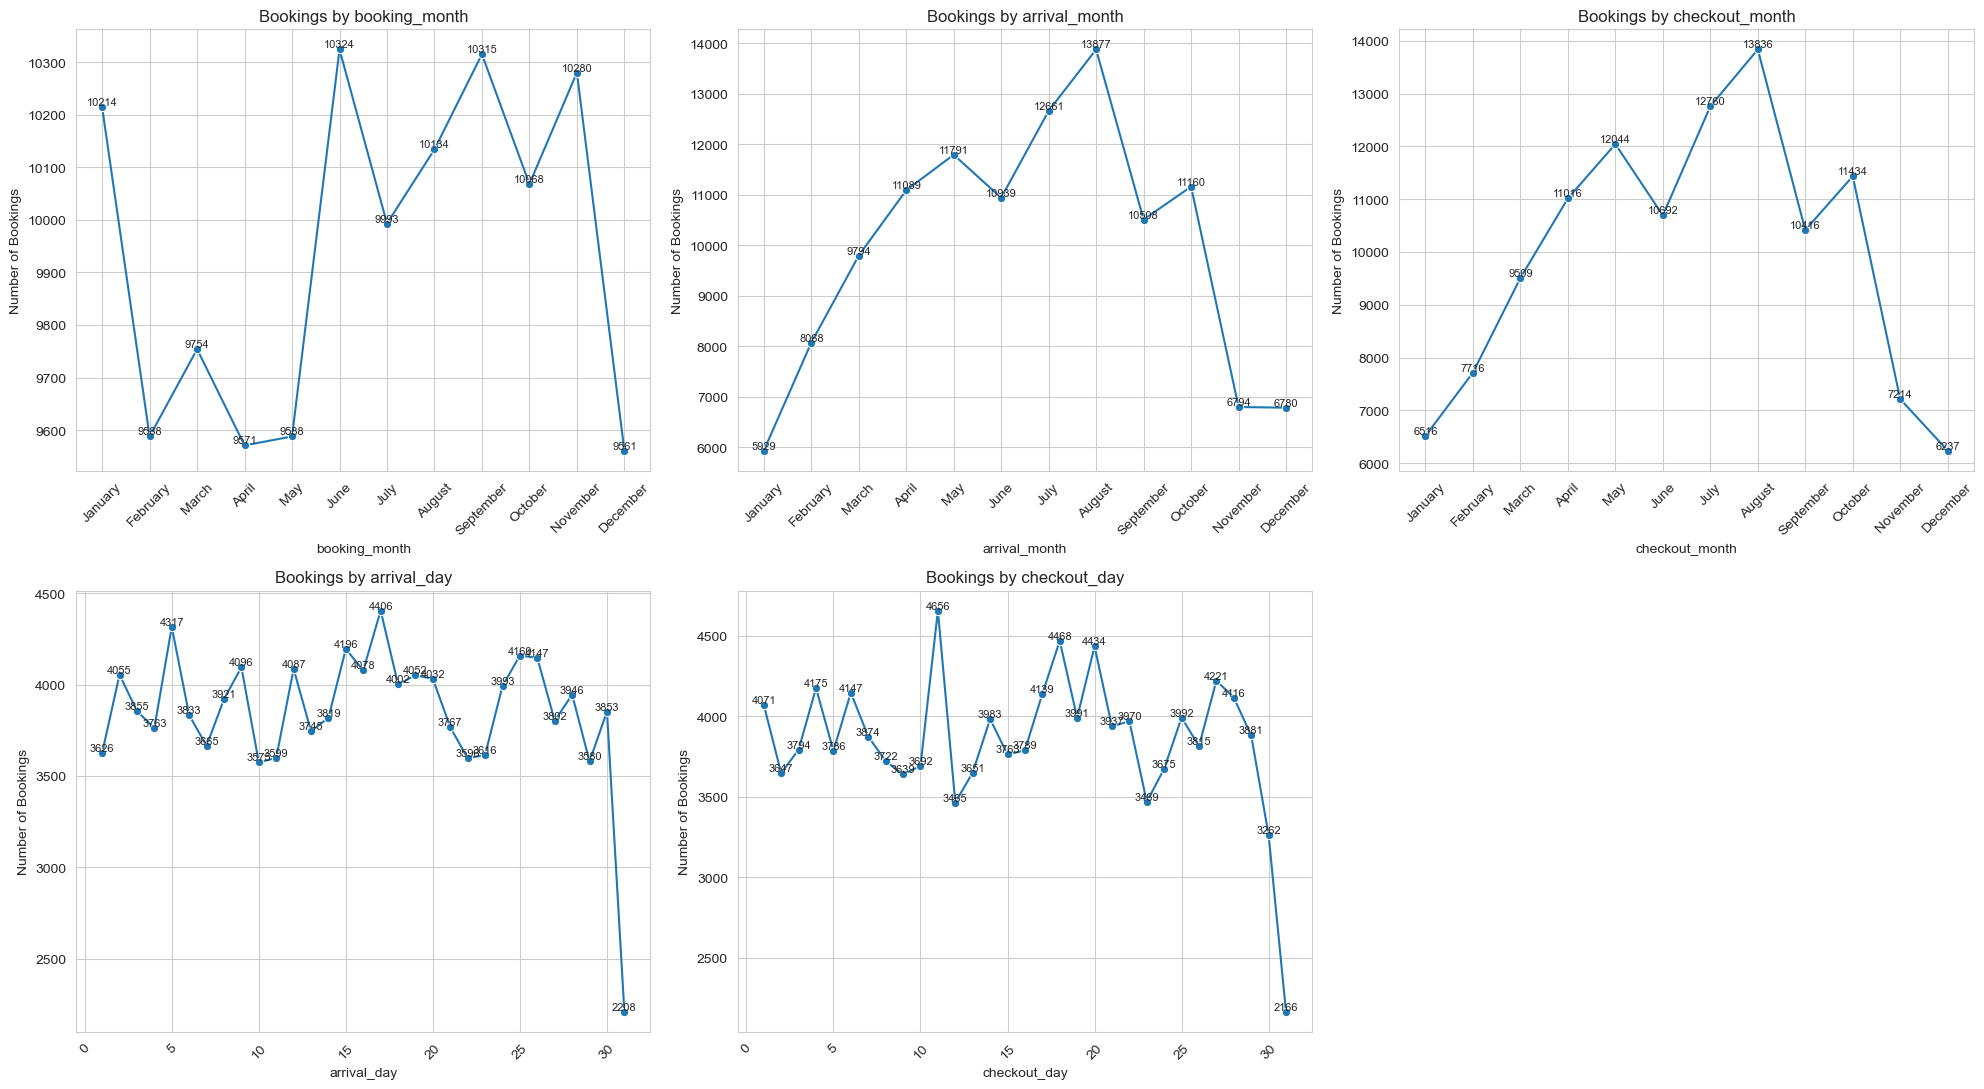

In [18]:
# Create line charts for 'booking_month', 'arrival_month', 'checkout_month', 'arrival_day' and'checkout_day'

# Calendar order for months (string months sort alphabetically otherwise)
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

month_cols = ['booking_month', 'arrival_month', 'checkout_month']
day_cols   = ['arrival_day', 'checkout_day']
all_cols   = month_cols + day_cols

sns.set_style("whitegrid")

# 2x3 grid: 3 months on top row, 2 days on bottom (6th cell unused)
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

for ax, col in zip(axes, all_cols):
    # Months -> reindex to calendar order; days -> sort_index() gives numeric 1..31
    if col in month_cols:
        counts = df[col].value_counts().reindex(month_order)
    else:
        counts = df[col].value_counts().sort_index()

    # Line chart of count vs ordered category
    sns.lineplot(x=counts.index, y=counts.values, marker='o', ax=ax)

    # Annotate each data point with its count
    for x, y in zip(counts.index, counts.values):
        ax.text(x, y, f'{int(y)}', ha='center', va='bottom', fontsize=8)

    ax.set_title(f'Bookings by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Bookings')
    ax.tick_params(axis='x', rotation=45)

# Hide the unused 6th subplot
axes[len(all_cols)].set_visible(False)

plt.tight_layout()
plt.show()

**Observations**:
- `arrival_month` and  `checkout_month` share strong mid year seasonality, both peaking in August. The similarity in distribution shapes suggest most bookings are for short term stays within the same month.

- `booking_month` is comparatively flat with no clear seasonal trend

- For `arrival_day` and `checkout_day`, the distribution is largely uniform with a ~50% dip at day 31, since only 7 months have day 31.

###  `num_adults`

In [19]:
# Inspect unique entries in `num_adults`
df['num_adults'].value_counts()

num_adults
1      62745
2      45243
one     6334
two     5068
Name: count, dtype: int64

In [20]:
# Fix num_adults: words mixed with digits (one/two -> 1/2), then make numeric
df['num_adults'] = df['num_adults'].replace({'one': 1, 'two': 2}).astype(int)

# Verify changes
df['num_adults'].value_counts()

num_adults
1    69079
2    50311
Name: count, dtype: int64

**Observation**: `num_adults` contain a mix of `str` ("one", "two") and `int` (1,2) values. After cleaning, it only takes two `int` values - 1 (~58%) and 2 (~42%) — effectively a binary feature. 

## Multivariate Analysis

### `room` and `price`

In [21]:
# Standardize price to SGD

def convert_price_to_sgd(price: pd.Series, usd_to_sgd: float = 1.37) -> pd.Series:
    """Convert a price column of 'SGD$ x' / 'USD$ x' strings to numeric SGD."""
    currency = price.str.extract(r'^([A-Z]+)')[0]                              # 'SGD' / 'USD' / NaN
    amount   = pd.to_numeric(price.str.replace(r'[^0-9.]', '', regex=True),    # numeric part
                             errors='coerce')
    return amount.where(currency != 'USD', amount * usd_to_sgd)                # scale only USD rows

df['price'] = convert_price_to_sgd(df['price'])

In [22]:
# Randomly inspect rows where either `room` or `price` has missing values
missing_room_or_price_rows = df['price'].isna() | df['room'].isna()
df[missing_room_or_price_rows].sample(10, random_state=42)

,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
1467,65388,1.0,Changi,March,September,24.0,September,26.0,China,Yes,King,NaN,Website,1,2.0
1277,74344,0.0,Changi,July,June,10.0,June,12.0,China,Yes,NaN,855.1677,Website,1,1.0
30615,94636,1.0,Changi,July,March,23.0,March,26.0,India,Yes,NaN,983.3300,Agent,1,0.0
53720,25507,0.0,Changi,June,August,3.0,August,5.0,Australia,Yes,King,NaN,Email,2,2.0
47865,83415,0.0,Orchard,August,August,23.0,August,27.0,India,Yes,NaN,1312.0500,Website,1,2.0
112616,110977,0.0,Orchard,February,February,18.0,February,19.0,Indonesia,Yes,NaN,1270.5106,Email,1,1.0
4793,16479,1.0,Changi,November,August,23.0,August,25.0,Singapore,Yes,NaN,545.8000,Website,1,1.0
75008,86198,0.0,Orchard,September,January,14.0,January,15.0,China,Yes,NaN,1477.4200,Phone,2,1.0
44125,115234,0.0,Changi,May,September,25.0,September,27.0,China,Yes,NaN,835.9877,Email,1,2.0
6459,22997,1.0,Changi,August,May,6.0,May,8.0,Indonesia,Yes,Single,NaN,Website,1,1.0


In [23]:
# Hypothesis: price and room are never both missing in the same row
both_missing = (df['price'].isna() & df['room'].isna()).sum()
print("Rows missing BOTH price and room:", both_missing)   # -> 0

Rows missing BOTH price and room: 0


**Observation**: From my random inspection of 10 rows that has missing values in either `price` or `room`, I suspect that `price` and `room` values are never missing in the same row. This hypothesis is confirmed to be true. 

**Conclusion**: Since `room` is always present when `price` is missing, I can impute values in `price` using `room` and vice versa. From domain knowledge, `branch` should also affect `price` so I can also consider using `branch` + `room` to impute `price`, or `branch` + `price` to impute `room`.

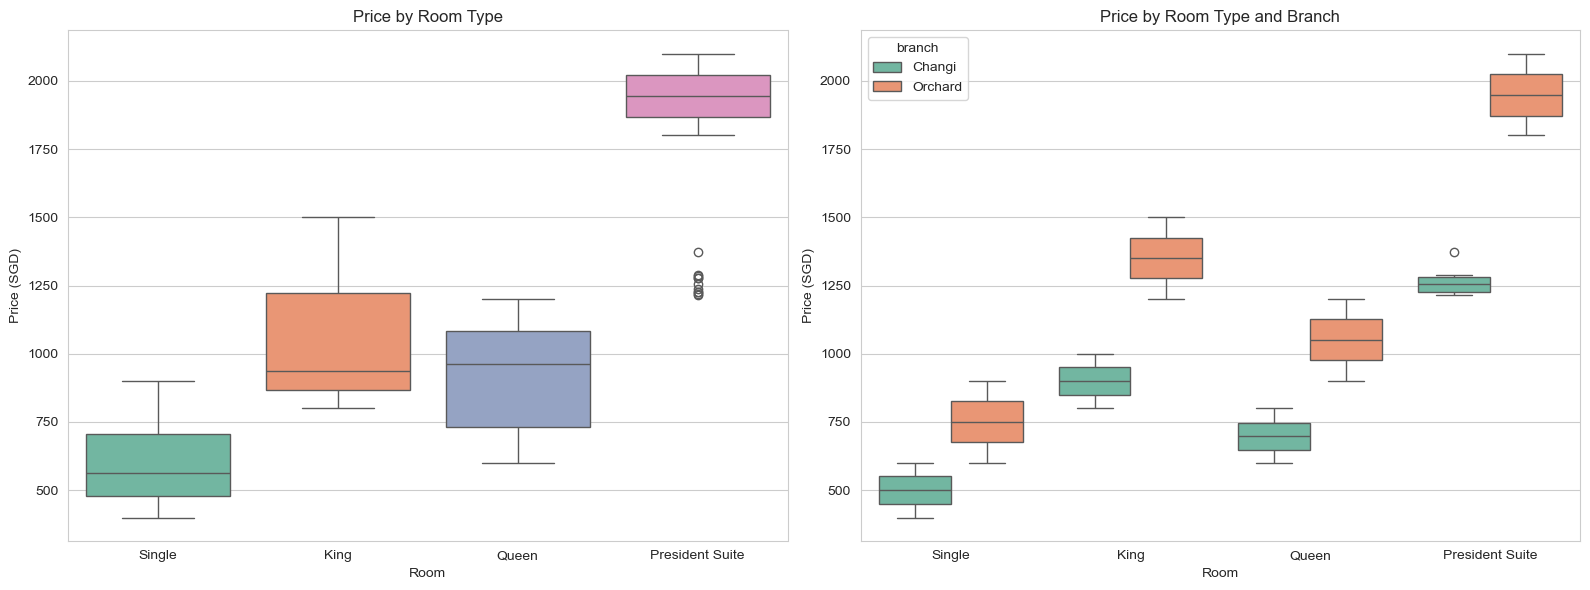

In [24]:
# Create box plot for `price` against `room`

## Set the aesthetic style of the plots
sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: coloured by room 
sns.boxplot(x='room', y='price', data=df, hue='room', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Price by Room Type')
axes[0].set_xlabel('Room'); axes[0].set_ylabel('Price (SGD)')

# Right: split by branch 
sns.boxplot(x='room', y='price', data=df, hue='branch', palette='Set2', ax=axes[1])
axes[1].set_title('Price by Room Type and Branch')
axes[1].set_xlabel('Room'); axes[1].set_ylabel('Price (SGD)')

plt.tight_layout()
plt.show()

**Observations**:

- `price` by `room` box plot:
    - Median price increases by room type: Single is cheapest and Presidential Suite is most expensive.
    - Price distribution for Single and President Suite rooms are distinct while those for King and Queen have significant overlapp
    - Presence of outliers for president suite. 

- `price` by `room` and `branch` box plot:
    - Splitting by `branch` sharply tightens each room's price distribution- useful for imputing `price` more accurately.
    - Orchard branch is consistently more expensive than Changi branch across all `room` types.
    - Within a single branch the room types separate cleanly by price, so `room` can be inferred from `branch` + `price` for majority (~98%) of bookings.

**Conclusion** :
- I will use `branch` + `room` median to impute missing `price` values.
- Also use `branch` + `price` to impute missing `room` values. 
- For `room` values that cannot be reliably imputed using `branch` + `price` , assign `Unknown` category.
- Outliers for presidential suite too small to warrant attention.




In [25]:
# Impute missing `price` values using `branch` + `room` median
def impute_price(df: pd.DataFrame) -> pd.DataFrame:
    """Fill missing price with the median price of its (branch, room) group."""
    df = df.copy()
    group_median = df.groupby(['branch', 'room'])['price'].transform('median')
    df['price'] = df['price'].fillna(group_median)
    return df

df = impute_price(df)

# Verify changes
df['price'].isna().sum()

np.int64(0)

In [26]:
# Impute missing `room` values using `branch` + `price`
def impute_room(df: pd.DataFrame) -> pd.DataFrame:
    """Impute missing room from branch + price band; assign 'Unknown' where ambiguous."""
    df = df.copy()

    # 1. Build price bands per (branch, room) from rows where room is KNOWN
    known = df.dropna(subset=['room'])
    bands = known.groupby(['branch', 'room'])['price'].quantile([0.01, 0.99]).unstack()
    bands.columns = ['lo', 'hi']

    # 2. For one row, find which room(s) its price falls into, within its branch
    def lookup_room(branch, price):
        if pd.isna(price):
            return 'Unknown'
        candidates = [room for (b, room), band in bands.iterrows()
                      if b == branch and band['lo'] <= price <= band['hi']]
        return candidates[0] if len(candidates) == 1 else 'Unknown'   # unique match, else Unknown

    # 3. Apply only to the missing-room rows
    missing = df['room'].isna()
    df.loc[missing, 'room'] = df.loc[missing].apply(
        lambda r: lookup_room(r['branch'], r['price']), axis=1)
    return df

df = impute_room(df)

# Verify changes 
df['room'].isna().sum()

np.int64(0)

**Observation**: Missing values for `room` and `price` were imputed successfully.

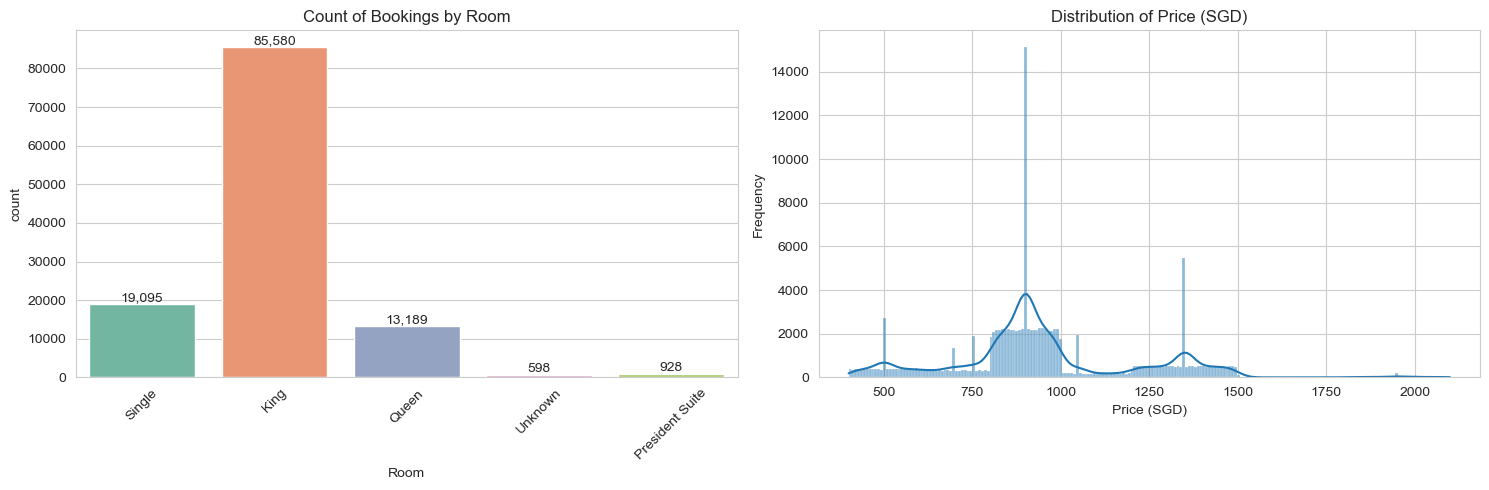

In [27]:
# Create bar chart for `room` and histogram for `price`
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: room (categorical bar chart)
sns.countplot(x='room', data=df, hue='room', palette='Set2', legend=False, ax=axes[0])
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='{:,.0f}')
axes[0].set_title('Count of Bookings by Room')
axes[0].set_xlabel('Room')
axes[0].tick_params(axis='x', rotation=45)

# Right: price (continuous histogram)
sns.histplot(df['price'], kde=True, ax=axes[1])
axes[1].set_title('Distribution of Price (SGD)')
axes[1].set_xlabel('Price (SGD)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

**Observations**:

- For `room` barchart: Majority of bookings (~72%) were for `King` rooms. Bookings for `President Suite` is rare (~0.8%). The imputed `Unknown` room category is a small proportion (~0.5%) of the data.
- For `price` histogram: Price ranges from ~300 SGD to ~2100 SGD with a multimodal shape. The sharp spikes (notably at ~900 and ~1,350) are due to imputation of missing `price` values.


### Multivariate analysis for `no_show` vs features (`branch`, `country`, `platform` etc)

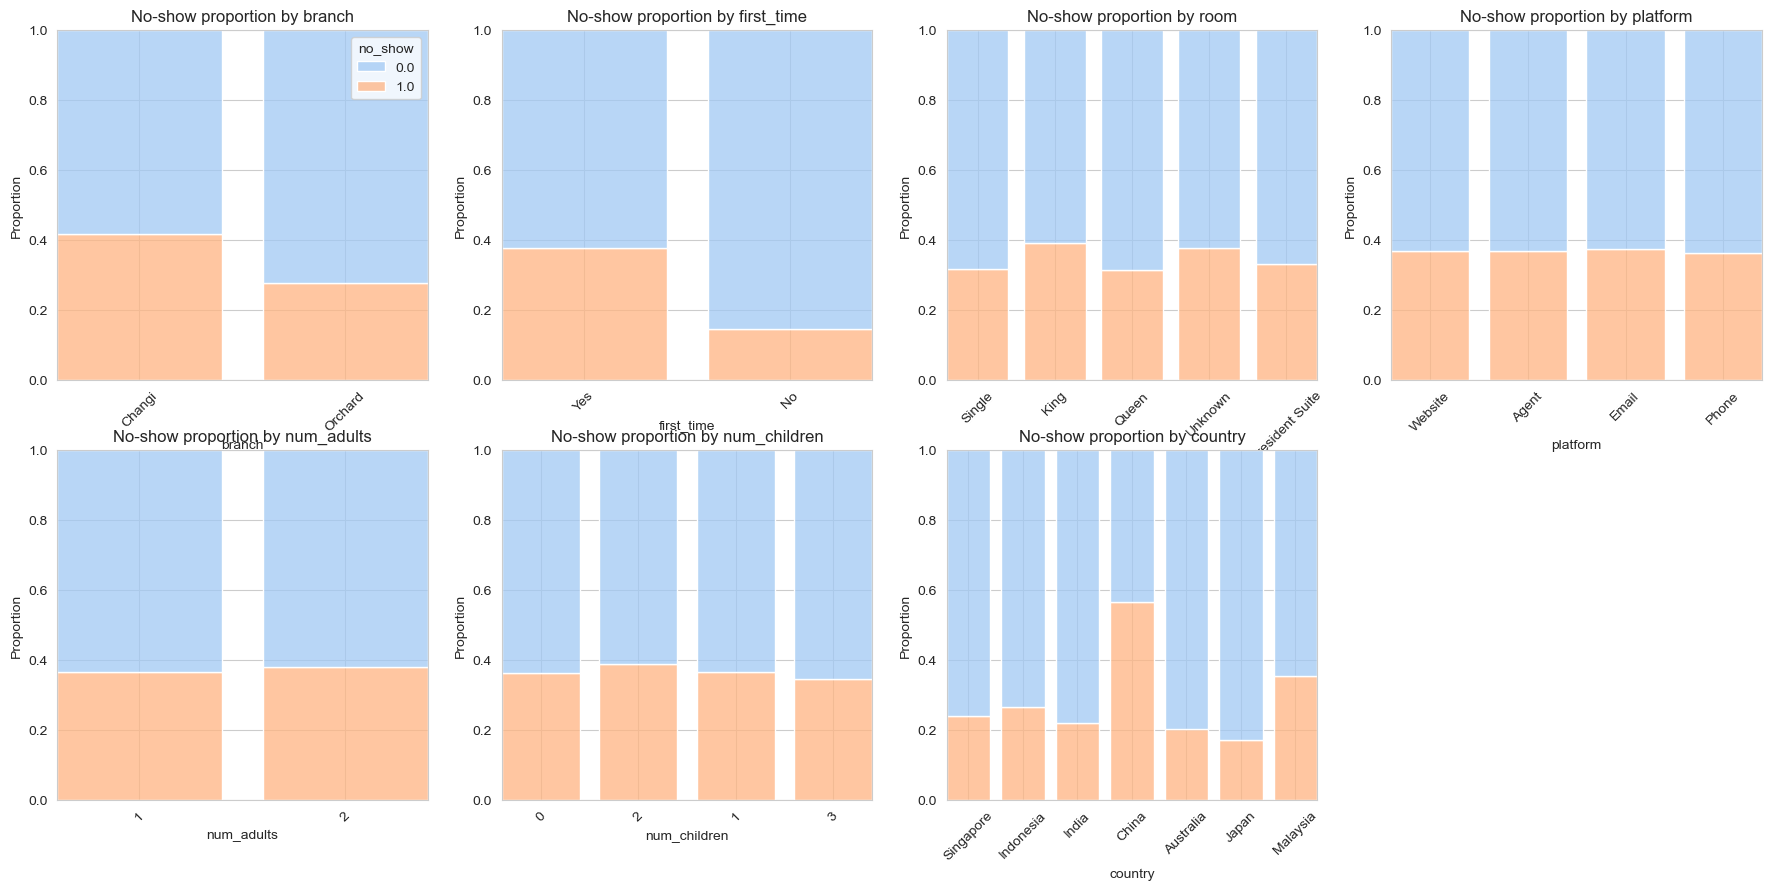

In [28]:
# Create normalized stacked barcharts to show No-show proportion within each feature 
sns.set_style("whitegrid")

cat_cols = ['branch', 'first_time', 'room', 'platform', 'num_adults', 'num_children', 'country']

# num_adults/num_children are numeric — cast to str so histplot treats each value as a category
plot_df = df.copy()
plot_df['num_adults'] = plot_df['num_adults'].astype(int).astype(str)
plot_df['num_children'] = plot_df['num_children'].astype(int).astype(str)

fig, axes = plt.subplots(2, 4, figsize=(22, 10))   # 2x4 = 8 panels for 7 columns
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.histplot(data=plot_df, x=col, hue='no_show', multiple='fill',
                 palette='pastel', shrink=0.8, ax=axes[i], legend=(i == 0))
    axes[i].set_title(f'No-show proportion by {col}')
    axes[i].set_xlabel(col); axes[i].set_ylabel('Proportion')
    axes[i].tick_params(axis='x', rotation=45)

# hide any unused panels (here, the 8th)
for j in range(len(cat_cols), len(axes)):
    axes[j].set_visible(False)

plt.show()

**Observations**:
- `country`,   `first_time` are strong predictors of no show signal. 
    - No-show rate ranges from China(~57%) to Japan (~17%) across countries. 
    - Repeat guests (`first_time` = No) no-show at only ~15% vs first-timers at ~38%.
- `branch` and `room` are moderate predictors.
- `platform`, `num_children` and `num_adults`  carry little to no signal (mostly noise).

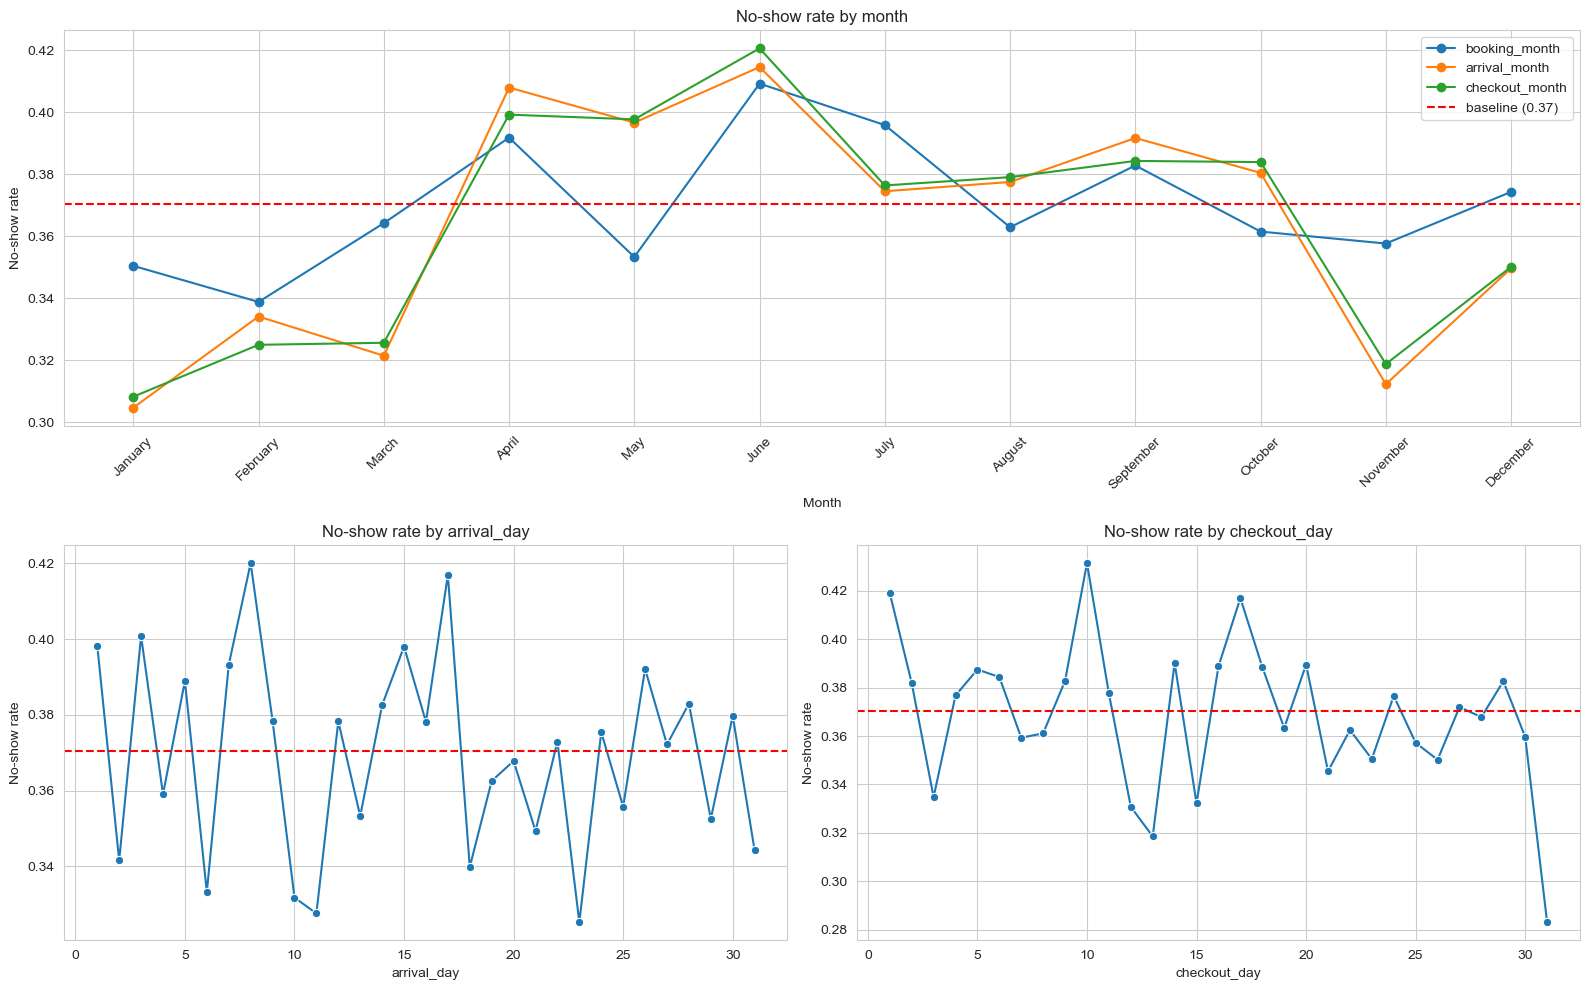

In [29]:
# Create linecharts to show for No-show rate for month and days

sns.set_style("whitegrid")
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
baseline = df['no_show'].mean()

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 2)
ax_month = fig.add_subplot(gs[0, :])     # top row, full width
ax_arr   = fig.add_subplot(gs[1, 0])     # bottom left
ax_chk   = fig.add_subplot(gs[1, 1])     # bottom right

# Top: no-show rate by month (three columns overlaid)
for col in ['booking_month', 'arrival_month', 'checkout_month']:
    rate = df.groupby(col)['no_show'].mean().reindex(month_order)
    ax_month.plot(month_order, rate.values, marker='o', label=col)
ax_month.axhline(baseline, color='red', linestyle='--', label='baseline (0.37)')
ax_month.set_title('No-show rate by month')
ax_month.set_xlabel('Month'); ax_month.set_ylabel('No-show rate')
ax_month.tick_params(axis='x', rotation=45); ax_month.legend()

# Bottom: no-show rate by day
for ax, col in [(ax_arr, 'arrival_day'), (ax_chk, 'checkout_day')]:
    rate = df.groupby(col)['no_show'].mean().sort_index()
    sns.lineplot(x=rate.index, y=rate.values, marker='o', ax=ax)
    ax.axhline(baseline, color='red', linestyle='--')
    ax.set_title(f'No-show rate by {col}')
    ax.set_xlabel(col); ax.set_ylabel('No-show rate')

plt.tight_layout()
plt.show()

**Observations**:

- `booking_month`, `arrival_month` and `checkout_month` carry weak but present signals for no-show prediction.
    - I see a mild seasonal pattern in no-show rate lowering in Jan–Mar (~31–36%), peaking around April–June (~40–42%) and dipping again in November. 
- `arrival_day` and `checkout_day` carry little to no signal (mostly noise).

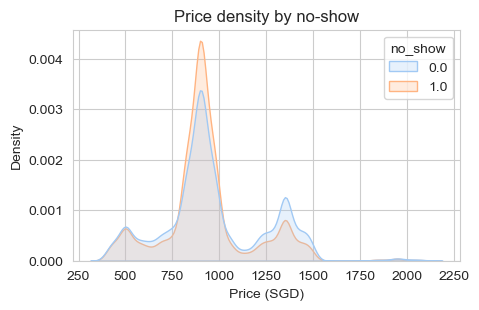

In [30]:
# Create KDE overlay plot for `price`
sns.set_style("whitegrid")
plt.figure(figsize=(5, 3))

sns.kdeplot(data=df, x='price', hue='no_show', palette='pastel', fill=True, common_norm=False)

plt.title('Price density by no-show')
plt.xlabel('Price (SGD)')
plt.show()

**Observations**: 
- Show and no-show distributions are nearly identical with same shape and peaks. 
- Price is not a reliable predictor of no-show.

## Feature Engineering

From domain knowledge we know that:
- Customers that book far in advance are more likely to cancel due to change in plans/unexpected circumstances -> Create new feature `lead_time` = `arrival_month` - `booking_month`.
    - Assume that `booking_month` is earlier than `arrival_month` and happens in same year.
    - If `lead_time` is negative, assume `booking_month` was in previous year.

In [31]:
# Create new feature `lead_time` 

# Convert month from str to int (Jan -> 1)
def month_to_num(month_series: pd.Series) -> pd.Series:
    """Map month names ('January'...'December') to numbers 1-12."""
    month_map = {m: i for i, m in enumerate([
        'January', 'February', 'March', 'April', 'May', 'June',
        'July', 'August', 'September', 'October', 'November', 'December'], start=1)}
    return month_series.map(month_map)

# Compute lead_time (in months) from arrival_month and booking_month
def compute_lead_time(df: pd.DataFrame) -> pd.Series:
    """Months between booking and arrival (0-11, year-wrap handled)."""
    lead = month_to_num(df['arrival_month']) - month_to_num(df['booking_month'])
    # if negative, booking was the previous year (e.g. booked Dec, arrive Feb) -> add 12
    return lead.where(lead >= 0, lead + 12)

df['lead_time'] = compute_lead_time(df)

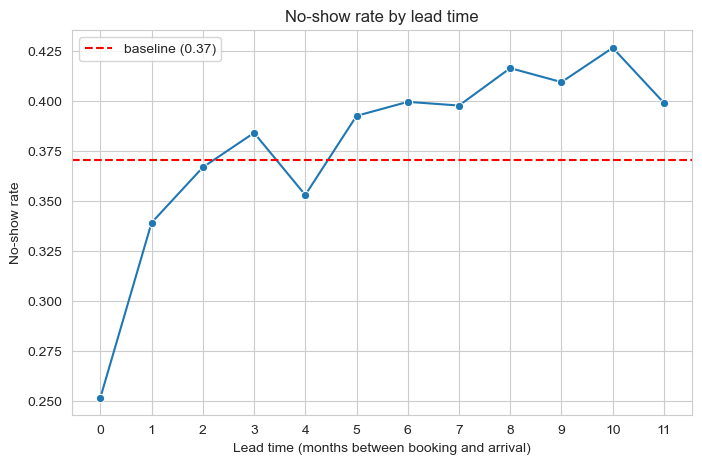

In [32]:
# Bivariate analysis for `no_show` vs `lead_time`
sns.set_style("whitegrid")
baseline = df['no_show'].mean()

plt.figure(figsize=(8, 5))
rate = df.groupby('lead_time')['no_show'].mean()
sns.lineplot(x=rate.index, y=rate.values, marker='o')
plt.axhline(baseline, color='red', linestyle='--', label='baseline (0.37)')

plt.title('No-show rate by lead time')
plt.xlabel('Lead time (months between booking and arrival)')
plt.ylabel('No-show rate')
plt.xticks(range(0, 12))
plt.legend()
plt.show()

**Observation**: 
- `lead_time` is a strong and robust predictor of no-show signal. 
- No-show rate climbs sharply from
  ~25% (same-month bookings) to ~37% by 2-3 months, then plateaus in the ~39-43% band
  for longer lead times
- Confirms hypothesis that customers who book far in advance are more likely to no-show.

## Feature Selection Based on Mutual Information

Mutual information measures the extent to which knowledge of one quanity reduces uncertainty about the other. It is good for ranking dependency of mixed features (categorical and numerical) on the target (no_show). I will use it for feature selection.

In [33]:
from sklearn.feature_selection import mutual_info_classif

cat = ['branch', 'country', 'first_time', 'room', 'platform',
       'booking_month', 'arrival_month', 'checkout_month']
num = ['lead_time', 'price', 'num_adults', 'num_children', 'arrival_day', 'checkout_day']

# Build feature matrix: encode categoricals as integer codes, mark which are discrete
X = pd.DataFrame()
discrete = []
for c in cat:
    X[c] = df[c].astype('category').cat.codes   # label-encode categories to integers
    discrete.append(True)
for c in num:
    X[c] = df[c]
    discrete.append(c != 'price')                # price is continuous, rest are discrete integers

mi = mutual_info_classif(X, df['no_show'], discrete_features=discrete, random_state=42)
ranking = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print(ranking.round(4))

country           0.0598
price             0.0100
branch            0.0095
lead_time         0.0058
first_time        0.0041
arrival_month     0.0025
checkout_month    0.0024
room              0.0024
checkout_day      0.0017
arrival_day       0.0014
booking_month     0.0009
num_children      0.0003
num_adults        0.0001
platform          0.0000
dtype: float64


**Observations**:

- `country`, `branch`, `lead_time`, `first_time`, `arrival_month`, `checkout_month`, `room` have non-zero MI score and rank in the top 50%. This agrees with my previous bivariate analysis that they carry predictive signals  -> Keep them.

- `price` ranks high with MI score of 0.01 but bivariate analysis shows it carries no observable signal. MI's weakness is in redundancy, which may explain the high MI for `price`. Nonetheless I will keep `price` as a feature. 

- `checkout_day`, `arrival_day`, `booking_month`, `num_children`, `num_adults`, `platform` ranks in the bottom 50% of MI score. Previous bivariate analysis confirms that they mostly carry noise and no meaningful signals -> Drop them.

- `booking_id` is just a row identifier and not included in MI analysis -> Drop it.

In [34]:
# Drop features: booking_id (row identifier) + low/no-signal columns (see MI + bivariate analysis)
drop_cols = ['booking_id', 'checkout_day', 'arrival_day', 'booking_month',
             'num_children', 'num_adults', 'platform']
df = df.drop(columns=drop_cols)

# Verify remaining features
df.columns   # verify remaining features

Index(['no_show', 'branch', 'arrival_month', 'checkout_month', 'country',
       'first_time', 'room', 'price', 'lead_time'],
      dtype='object')